In [1]:
import pandas as pd

df = pd.read_csv("data.csv")
print(df.shape)
df.head(10)

(32, 5)


,Duration,Date,Pulse,Maxpulse,Calories
0,60,'2020/12/01',110,130,409.1
1,60,'2020/12/02',117,145,479.0
2,60,'2020/12/03',103,135,340.0
3,45,'2020/12/04',109,175,282.4
4,45,'2020/12/05',117,148,406.0
5,60,'2020/12/06',102,127,300.0
6,60,'2020/12/07',110,136,374.0
7,450,'2020/12/08',104,134,253.3
8,30,'2020/12/09',109,133,195.1
9,60,'2020/12/10',98,124,269.0


In [2]:
print("Missing values:")
print(df.isna().sum())
print()
print("Duplicate rows:", df.duplicated().sum())
print()
df.describe()

Missing values:
Duration    0
Date        1
Pulse       0
Maxpulse    0
Calories    2
dtype: int64

Duplicate rows: 1



,Duration,Pulse,Maxpulse,Calories
count,32.000000,32.000000,32.000000,30.000000
mean,68.437500,103.500000,128.500000,304.680000
std,70.039591,7.832933,12.998759,66.003779
min,30.000000,90.000000,101.000000,195.100000
25%,60.000000,100.000000,120.000000,250.700000
50%,60.000000,102.500000,127.500000,291.200000
75%,60.000000,106.500000,132.250000,343.975000
max,450.000000,130.000000,175.000000,479.000000


In [3]:
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)
print("Duplicate rows now:", df.duplicated().sum())

(31, 5)
Duplicate rows now: 0


In [4]:
df["Date"] = df["Date"].str.replace("'", "", regex=False)
df["Date"] = pd.to_datetime(df["Date"], format="mixed")
df = df.dropna(subset=["Date"]).reset_index(drop=True)
print(df.shape)
print(df.dtypes)
df.head()

(30, 5)
Duration             int64
Date        datetime64[us]
Pulse                int64
Maxpulse             int64
Calories           float64
dtype: object


,Duration,Date,Pulse,Maxpulse,Calories
0,60,2020-12-01,110,130,409.1
1,60,2020-12-02,117,145,479.0
2,60,2020-12-03,103,135,340.0
3,45,2020-12-04,109,175,282.4
4,45,2020-12-05,117,148,406.0


In [5]:
median_calories = df["Calories"].median()
print("Median Calories:", median_calories)

df.loc[df["Duration"] == 450, "Duration"] = 45

df["Calories"] = df["Calories"].fillna(median_calories)

print(df.isna().sum())
print("Max Duration:", df["Duration"].max())

Median Calories: 300.0
Duration    0
Date        0
Pulse       0
Maxpulse    0
Calories    0
dtype: int64
Max Duration: 60


In [6]:
import numpy as np

df["Calories_per_min"] = (df["Calories"] / df["Duration"]).round(2)
df["Weekday"] = df["Date"].dt.day_name()
df["Intensity"] = np.where(df["Calories_per_min"] >= 6, "High",
                  np.where(df["Calories_per_min"] >= 5, "Medium", "Low"))

print(df["Intensity"].value_counts())
df.head()

Intensity
Medium    12
High      10
Low        8
Name: count, dtype: int64


,Duration,Date,Pulse,Maxpulse,Calories,Calories_per_min,Weekday,Intensity
0,60,2020-12-01,110,130,409.1,6.82,Tuesday,High
1,60,2020-12-02,117,145,479.0,7.98,Wednesday,High
2,60,2020-12-03,103,135,340.0,5.67,Thursday,Medium
3,45,2020-12-04,109,175,282.4,6.28,Friday,High
4,45,2020-12-05,117,148,406.0,9.02,Saturday,High


In [7]:
hard_workouts = df[(df["Duration"] >= 60) & (df["Calories"] >= 300)]
print("Workouts with 60+ minutes and 300+ calories:", len(hard_workouts))
hard_workouts

Workouts with 60+ minutes and 300+ calories: 15


,Duration,Date,Pulse,Maxpulse,Calories,Calories_per_min,Weekday,Intensity
0,60,2020-12-01,110,130,409.1,6.82,Tuesday,High
1,60,2020-12-02,117,145,479.0,7.98,Wednesday,High
2,60,2020-12-03,103,135,340.0,5.67,Thursday,Medium
5,60,2020-12-06,102,127,300.0,5.00,Sunday,Medium
6,60,2020-12-07,110,136,374.0,6.23,Monday,High
10,60,2020-12-11,103,147,329.3,5.49,Friday,Medium
12,60,2020-12-13,106,128,345.3,5.76,Sunday,Medium
13,60,2020-12-14,104,132,379.3,6.32,Monday,High
16,60,2020-12-17,100,120,300.0,5.00,Thursday,Medium
18,60,2020-12-19,103,123,323.0,5.38,Saturday,Medium


In [8]:
df.to_csv("cleaned_data.csv", index=False)
print("Saved:", df.shape)

Saved: (30, 8)


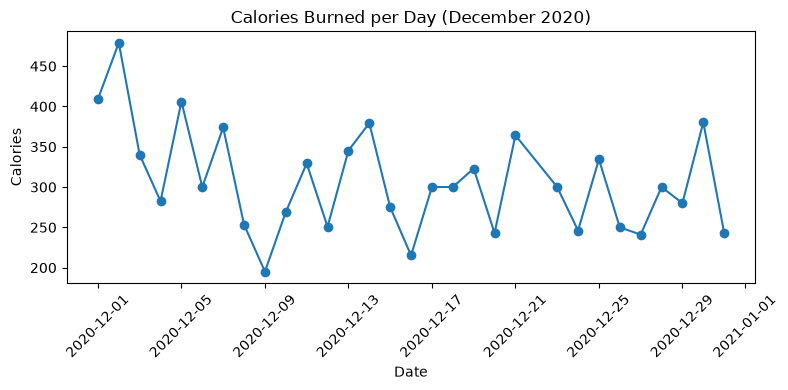

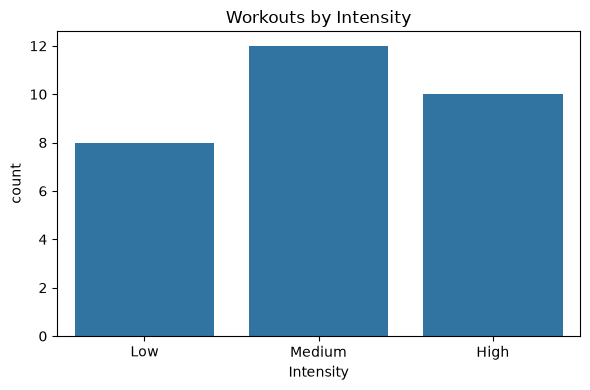

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))
plt.plot(df["Date"], df["Calories"], marker="o")
plt.title("Calories Burned per Day (December 2020)")
plt.xlabel("Date")
plt.ylabel("Calories")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("calories_over_time.png")
plt.show()

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Intensity", order=["Low", "Medium", "High"])
plt.title("Workouts by Intensity")
plt.tight_layout()
plt.savefig("intensity_counts.png")
plt.show()